# F2_02 · Exploración de faltantes y valores desconocidos
**MCDIA500 · Programación para la Ciencia de Datos · Grupo 2**

**Objetivo.** Cuantificar los valores faltantes, desconocidos (códigos 96/99) y enmascarados (`*`) en los egresos por colelitiasis (K80.0–K80.8) de la Región de La Araucanía (DEIS, 2022), y describir su distribución por sexo y grupo de edad.

**Supuestos.** Se trabaja con el archivo procesado de La Araucanía (`data/processed/egresos_araucania_2022.csv`), derivado de la base abierta de egresos 2022; los valores se leen como texto (`dtype=str`) para no perder los ceros de los códigos ni valores como `*`, `96` o `99`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Raíz del repositorio (el notebook se ejecuta desde la carpeta F2/)
RAIZ = Path.cwd()
if RAIZ.name.startswith("F"):
    RAIZ = RAIZ.parent
RUTA = RAIZ / "data" / "processed" / "egresos_araucania_2022.csv"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

## 1. Carga y filtro
El archivo procesado contiene todos los egresos de La Araucanía; aquí se filtran los diagnósticos K80.0–K80.8.

In [2]:
df = pd.read_csv(RUTA, dtype=str, keep_default_na=False)
df = df.apply(lambda s: s.str.strip())
print(f"Egresos de La Araucanía en el archivo: {len(df)}")

datos = df[df["DIAG1"].str.upper().str.match(r"^K80[0-8]")].copy()
n = len(datos)
print(f"Egresos K80.0-K80.8: {n}")

Egresos de La Araucanía en el archivo: 84618
Egresos K80.0-K80.8: 3789


## 2. Faltantes por variable
Se cuentan, por separado, los vacíos, los enmascarados (`*`) y los desconocidos (`PREVISION` = 99 o glosa «DESCONOCIDO»).

In [3]:
def es_desconocido(col, s):
    if col == "PREVISION":
        return s == "99"
    return s.str.upper().isin(["DESCONOCIDO", "IGNORADA", "IGNORADO"])

filas = []
for c in datos.columns:
    s = datos[c]
    filas.append({
        "variable": c,
        "vacios": int((s == "").sum()),
        "enmascarados_*": int((s == "*").sum()),
        "desconocido": int(es_desconocido(c, s).sum()),
    })
tabla = pd.DataFrame(filas)
for col in ["vacios", "enmascarados_*", "desconocido"]:
    tabla["%_" + col] = (tabla[col] / n * 100).round(1)
tabla

,variable,vacios,enmascarados_*,desconocido,%_vacios,%_enmascarados_*,%_desconocido
0,PERTENENCIA_ESTABLECIMIENTO_SALUD,0,0,0,0.0,0.0,0.0
1,SEXO,0,0,0,0.0,0.0,0.0
2,GRUPO_EDAD,0,0,0,0.0,0.0,0.0
3,ETNIA,0,0,0,0.0,0.0,0.0
4,GLOSA_PAIS_ORIGEN,0,0,0,0.0,0.0,0.0
5,COMUNA_RESIDENCIA,0,0,0,0.0,0.0,0.0
6,GLOSA_COMUNA_RESIDENCIA,0,0,0,0.0,0.0,0.0
7,REGION_RESIDENCIA,0,0,0,0.0,0.0,0.0
8,GLOSA_REGION_RESIDENCIA,0,0,0,0.0,0.0,0.0
9,PREVISION,0,0,160,0.0,0.0,4.2


**Lectura.** `DIAG2` (causa externa) solo se informa en traumatismos y lesiones, por lo que está vacío en todos los egresos por colelitiasis; es un vacío esperado y no se imputa. `GLOSA_INTERV_Q_PPAL` vacía indica ausencia de intervención quirúrgica, no un dato perdido: para la marca de colecistectomía corresponde codificarla como «No». `GLOSA_PROCED_PPAL` vacía indica que no se registró procedimiento.

## 3. Valores desconocidos 96/99 y enmascarados `*`

In [4]:
prev = (datos.groupby(["PREVISION", "GLOSA_PREVISION"]).size()
        .rename("egresos").reset_index())
prev["%"] = (prev["egresos"] / n * 100).round(1)
print("Previsión (96 = NINGUNA, 99 = DESCONOCIDO):")
display(prev)
n_9699 = datos["PREVISION"].isin(["96", "99"]).sum()
print(f"Criterio del grupo: 96/99 = desconocido -> {n_9699} egresos ({n_9699/n*100:.1f}%)")

mask = datos["REGION_RESIDENCIA"] == "*"
print(f"Egresos enmascarados (*): {mask.sum()} ({mask.mean()*100:.1f}%)")

Previsión (96 = NINGUNA, 99 = DESCONOCIDO):


,PREVISION,GLOSA_PREVISION,egresos,%
0,1,FONASA,3193,84.3
1,2,ISAPRE,367,9.7
2,4,DIPRECA,32,0.8
3,5,SISA,11,0.3
4,96,NINGUNA,26,0.7
5,99,DESCONOCIDO,160,4.2


Criterio del grupo: 96/99 = desconocido -> 186 egresos (4.9%)
Egresos enmascarados (*): 0 (0.0%)


### 3.1 ¿Se concentran los desconocidos en algún grupo?
Si se concentran, pueden sesgar la comparación entre Malleco y Cautín.

In [5]:
datos["PROVINCIA"] = datos["COMUNA_RESIDENCIA"].map(
    lambda c: "Malleco" if c.startswith("092") else "Cautín")
datos["PREV_DESCONOCIDA"] = datos["PREVISION"] == "99"

por_prov = (datos.groupby("PROVINCIA")
            .agg(egresos=("PREV_DESCONOCIDA", "size"),
                 prev_desconocida=("PREV_DESCONOCIDA", "sum")))
por_prov["% desconocida"] = (por_prov["prev_desconocida"] / por_prov["egresos"] * 100).round(1)
por_prov

,egresos,prev_desconocida,% desconocida
PROVINCIA,,,
Cautín,3017,3,0.1
Malleco,772,157,20.3


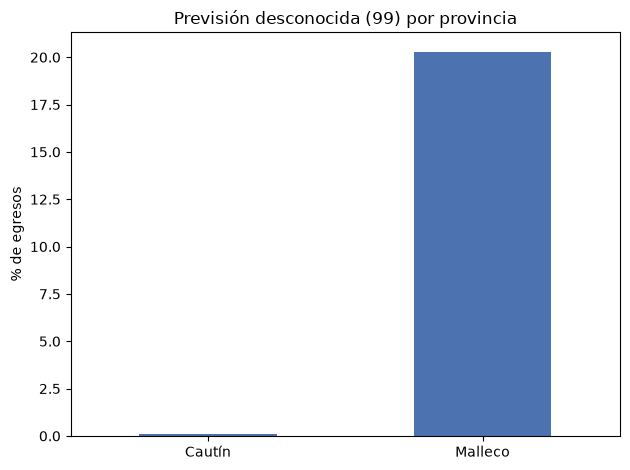

In [6]:
ax = por_prov["% desconocida"].plot(kind="bar", color="#4C72B0", rot=0)
ax.set_title("Previsión desconocida (99) por provincia")
ax.set_ylabel("% de egresos")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

## 4. Distribución por sexo y grupo de edad
Se excluyen aquí los egresos con sexo o edad enmascarados (`*`), que se informan aparte.

In [7]:
validos = datos[(datos["SEXO"] != "*") & (datos["GRUPO_EDAD"] != "*")]
print(f"Egresos con sexo y edad informados: {len(validos)}  |  excluidos por *: {n - len(validos)}")

sexo = validos["SEXO"].value_counts().rename("egresos").to_frame()
sexo["%"] = (sexo["egresos"] / len(validos) * 100).round(1)
display(sexo)

orden = ["1 a 9", "10 a 19", "20 a 29", "30 a 39", "40 a 49",
         "50 a 59", "60 a 69", "70 a 79", "80 a 89", "90 y más"]
cruce = pd.crosstab(validos["GRUPO_EDAD"], validos["SEXO"]).reindex(orden)
cruce

Egresos con sexo y edad informados: 3789  |  excluidos por *: 0


,egresos,%
SEXO,,
MUJER,2764,72.9
HOMBRE,1025,27.1


SEXO,HOMBRE,MUJER
GRUPO_EDAD,,
1 a 9,4,1
10 a 19,29,102
20 a 29,59,396
30 a 39,146,564
40 a 49,151,497
50 a 59,203,480
60 a 69,206,413
70 a 79,150,198
80 a 89,66,89


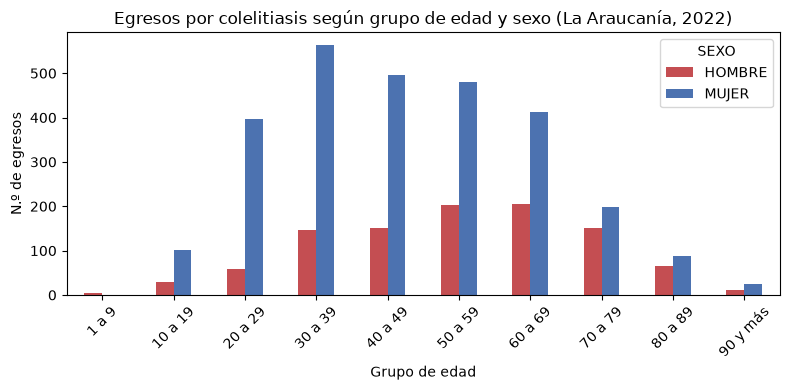

In [8]:
ax = cruce.plot(kind="bar", color=["#C44E52", "#4C72B0"], rot=45, figsize=(8, 4))
ax.set_title("Egresos por colelitiasis según grupo de edad y sexo (La Araucanía, 2022)")
ax.set_ylabel("N.º de egresos")
ax.set_xlabel("Grupo de edad")
plt.tight_layout()
plt.show()

## 5. Filas repetidas
La base es anónima, por lo que filas idénticas corresponden a egresos distintos. Se cuantifican, pero **no se eliminan**.

In [9]:
dup = datos.duplicated(keep=False)
primeras = datos.duplicated(keep="first")
print(f"Egresos que forman parte de un grupo de filas idénticas: {dup.sum()} ({dup.mean()*100:.1f}%)")
print(f"Filas repetidas respecto de una primera aparición: {primeras.sum()} ({primeras.mean()*100:.1f}%)")

Egresos que forman parte de un grupo de filas idénticas: 1663 (43.9%)
Filas repetidas respecto de una primera aparición: 1276 (33.7%)


## 6. Distribución por etnia y provincia

In [10]:
valid_etnia = datos[datos["ETNIA"] != "*"]
etnia = valid_etnia["ETNIA"].value_counts().rename("egresos").to_frame()
etnia["%"] = (etnia["egresos"] / len(valid_etnia) * 100).round(1)
display(etnia)

prov = datos["PROVINCIA"].value_counts().rename("egresos").to_frame()
prov["%"] = (prov["egresos"] / n * 100).round(1)
display(prov)

display(pd.crosstab(datos["PROVINCIA"], datos["ETNIA"], normalize="index").mul(100).round(1))

,egresos,%
ETNIA,,
No se identifica con alguna etnia,3036,80.1
Si se identifica con alguna etnia,753,19.9


,egresos,%
PROVINCIA,,
Cautín,3017,79.6
Malleco,772,20.4


ETNIA,No se identifica con alguna etnia,Si se identifica con alguna etnia
PROVINCIA,,
Cautín,79.0,21.0
Malleco,84.5,15.5


## 7. Decisiones y limitaciones
- **Filtro por región.** El archivo procesado incluye solo egresos con región de residencia 09; los egresos con región enmascarada (`*`) pero comuna de La Araucanía (70 en K80.0–K80.8 en la base nacional) quedan fuera, lo que se declara como limitación.
- **Enmascarados.** Si aparecen, se excluyen únicamente de los análisis que usen sexo, edad o previsión.
- **Previsión desconocida (99).** Se concentra en Malleco, por lo que se evitará usar la previsión como variable de ajuste y se declarará como limitación en el README.
- **Filas repetidas.** Se cuantifican y no se eliminan, porque la base es anónima y filas idénticas son egresos distintos.
- **96/99.** Siguiendo el acuerdo del grupo, ambos códigos se tratan como «desconocido» (96 corresponde a «NINGUNA» en la glosa de previsión) y se distinguen de los vacíos (NaN).
- **Intervención vacía.** Se interpreta como «sin colecistectomía», no como dato faltante.